<a href="https://colab.research.google.com/github/WAZNY-HS/CODSOFT/blob/main/Participants_of_FL_Workshop_Part3_Guided_Demonstration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Federated Learning: Guided Demonstration
**Part 3 · University of Sri Jayewardenepura workshop**

Ten hospitals want to train one model that reads handwritten digits. No hospital may send its images to anyone. We will see whether they can still train a good model together.

**How to use this notebook**
1. Select **File > Save a copy in Drive**.
2. Run each cell in order with **Shift + Enter**.
3. Read the text above each cell before you run it.

## Setup (2 minutes)
Run the two cells below. You do not need to read them. Wait until you see **Setup complete**.

In [ ]:
%%capture
# Install Flower (about one minute). Output is hidden on purpose.
!pip install -q "flwr[simulation]==1.44.0"

In [ ]:
#@title Setup: run this cell (no need to read the code)
# ============================================================
# SETUP: run this cell once. You do not need to read it.
# It loads the data, defines the model, and connects to Flower.
# ============================================================
import os, time, logging, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

logging.getLogger("flwr").setLevel(logging.ERROR)
logging.getLogger("ray").setLevel(logging.ERROR)
os.environ["RAY_DEDUP_LOGS"] = "0"
os.environ["RAY_DISABLE_IMPORT_WARNING"] = "1"

from flwr.app import ArrayRecord, Context, Message, MetricRecord, RecordDict
from flwr.clientapp import ClientApp
from flwr.serverapp import Grid, ServerApp
from flwr.serverapp.strategy import FedAvg, FedProx
from flwr.simulation import run_simulation
logging.getLogger("flwr").setLevel(logging.ERROR)
for h in logging.getLogger("flwr").handlers:
    h.setLevel(logging.ERROR)

torch.manual_seed(42); np.random.seed(42)

# ---------- Data: MNIST handwritten digits ----------
TRAIN_SIZE = 30000  #@param {type:"integer"}
DATA_PATH = os.path.abspath("mnist_tensors.pt")

def _load_mnist():
    from torchvision import datasets
    tr = datasets.MNIST("data", train=True, download=True)
    te = datasets.MNIST("data", train=False, download=True)
    def prep(ds, n=None):
        x = ((ds.data.float() / 255.0 - 0.1307) / 0.3081).unsqueeze(1)
        y = ds.targets.clone()
        return (x[:n], y[:n]) if n else (x, y)
    return prep(tr, TRAIN_SIZE) + prep(te)

train_images, train_labels, test_images, test_labels = _load_mnist()
torch.save({"x": train_images, "y": train_labels}, DATA_PATH)
_test_loader = DataLoader(TensorDataset(test_images, test_labels), batch_size=500)

# ---------- The model: a simple neural network ----------
class Net(nn.Module):
    """784 pixels in -> 128 hidden units -> 10 outputs (one per digit)."""
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(28 * 28, 128)
        self.output = nn.Linear(128, 10)
    def forward(self, x):
        return self.output(F.relu(self.hidden(x.flatten(1))))

def train(model, images, labels, epochs=1, mu=0.0):
    """Teach the model using these images. mu > 0 is only for FedProx."""
    start = [p.detach().clone() for p in model.parameters()]
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    loader = DataLoader(TensorDataset(images, labels), batch_size=32, shuffle=True)
    model.train()
    for _ in range(epochs):
        for x, y in loader:
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            if mu > 0:
                loss = loss + (mu / 2) * sum(((p - s) ** 2).sum() for p, s in zip(model.parameters(), start))
            loss.backward(); opt.step()

def test(model):
    """Mark the model on the 10,000 test images. Returns accuracy from 0 to 1."""
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in _test_loader:
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(test_labels)

# ---------- Pictures ----------
def show_digits(images, labels, predictions=None, n=10, title=""):
    plt.figure(figsize=(n * 1.2, 1.8))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[i][0].numpy(), cmap="gray_r"); plt.axis("off")
        if predictions is None:
            plt.title(f"This is a {labels[i].item()}", fontsize=10)
        else:
            ok = predictions[i] == labels[i].item()
            plt.title(f"Model says {predictions[i]}\n{'Correct' if ok else 'Wrong'}", fontsize=9,
                      color="green" if ok else "red")
    if title: plt.suptitle(title, y=1.15)
    plt.show()

def show_clients(clients, title):
    counts = np.array([[int((train_labels[c] == d).sum()) for d in range(10)] for c in clients])
    plt.figure(figsize=(8, 0.35 * len(clients) + 1.5))
    plt.imshow(counts, cmap="Blues", aspect="auto")
    plt.colorbar(label="Number of images (darker = more)")
    plt.xticks(range(10)); plt.xlabel("Digit (0 to 9)")
    plt.yticks(range(len(clients)), [f"Hospital {i+1}" for i in range(len(clients))])
    plt.title(title); plt.tight_layout(); plt.show()

def plot_results(results, baseline=None):
    plt.figure(figsize=(8, 4.5))
    for name, accs in results.items():
        plt.plot(range(len(accs)), [a * 100 for a in accs], marker="o", label=name)
    if baseline is not None:
        plt.axhline(baseline * 100, ls="--", color="grey", label="Normal training (all data collected)")
    plt.title("How many test images does the model get right?")
    plt.xticks(range(max(len(v) for v in results.values())))
    plt.xlabel("Training round"); plt.ylabel("Test images correct (%)"); plt.ylim(0, 100)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------- Splitting the data across clients ----------
def split_data(num_clients=10, how="even", alpha=0.5, seed=42):
    """even: every client gets a similar mix of digits.
       uneven: each client gets mostly a few digits (smaller alpha = more uneven)."""
    rng = np.random.default_rng(seed); labels = train_labels.numpy()
    if how == "even":
        return [p.tolist() for p in np.array_split(rng.permutation(len(labels)), num_clients)]
    while True:
        parts = [[] for _ in range(num_clients)]
        for d in range(10):
            idx = np.where(labels == d)[0]; rng.shuffle(idx)
            cuts = (np.cumsum(rng.dirichlet([alpha] * num_clients)) * len(idx)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= 20:
            return parts

# ---------- Flower: connects the clients and the server ----------
def run_federated(clients, rounds=5, fraction=1.0, method="FedAvg", mu=0.1, quiet=False):
    """Runs federated learning. Returns the test accuracy after each round."""
    data_path, num_clients = DATA_PATH, len(clients)
    history = []
    app_c = ClientApp()

    @app_c.train()
    def _flower_client(msg: Message, context: Context):
        d = torch.load(data_path)
        mine = torch.tensor(clients[int(context.node_config["partition-id"])])
        weights = msg.content["arrays"].to_torch_state_dict()
        if method == "FedProx":
            model = Net(); model.load_state_dict(weights)
            train(model, d["x"][mine], d["y"][mine], mu=mu)
            new_weights, n = model.state_dict(), len(mine)
        else:
            new_weights, n = client_training(weights, d["x"][mine], d["y"][mine])
        return Message(RecordDict({"arrays": ArrayRecord(new_weights),
                                   "metrics": MetricRecord({"num-examples": n})}), reply_to=msg)

    def _check(rnd, arrays):
        model = Net(); model.load_state_dict(arrays.to_torch_state_dict())
        acc = test(model); history.append(acc)
        if not quiet:
            if rnd == 0:
                print(f"Round 0: before any training .......................... {acc:6.1%} correct")
            else:
                k = max(1, round(fraction * num_clients))
                print(f"Round {rnd}: {k:2d} hospitals trained, server averaged them ... {acc:6.1%} correct")
        return MetricRecord({"accuracy": acc})

    app_s = ServerApp()

    @app_s.main()
    def _flower_server(grid: Grid, context: Context):
        S = FedProx if method == "FedProx" else FedAvg
        kw = dict(fraction_train=fraction, fraction_evaluate=0.0, min_train_nodes=1,
                  min_available_nodes=num_clients)
        if method == "FedProx":
            kw["proximal_mu"] = mu
        S(**kw).start(grid=grid, initial_arrays=ArrayRecord(Net().state_dict()),
                      num_rounds=rounds, evaluate_fn=_check)

    t = time.time()
    run_simulation(server_app=app_s, client_app=app_c, num_supernodes=num_clients,
                   backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0},
                                   "init_args": {"logging_level": logging.ERROR,
                                                 "log_to_driver": False}})
    if not quiet:
        print(f"Finished in {time.time() - t:.0f} seconds. No hospital shared any image.")
    return history

def client_training(global_weights, my_images, my_labels):
    """Placeholder; the notebook defines the real one in Step 4."""
    raise RuntimeError("Run the Step 4 cell first.")

print(f"Setup complete. {len(train_labels):,} training images and {len(test_labels):,} test images loaded.")

  0%|          | 0.00/9.91M [00:00<?, ?B/s]/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
100%|██████████| 9.91M/9.91M [00:00<00:00, 58.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.39MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.97MB/s]


Setup complete. 30,000 training images and 10,000 test images loaded.


## Step 1. Look at the data
We use MNIST, a standard set of handwritten digits. Each image is 28 × 28 pixels and shows one digit, 0 to 9. Every image comes with its correct answer, called a **label**.

The images are in two groups:
- **Training images (30,000):** used to teach the model.
- **Test images (10,000):** the exam. The model never trains on them. We use their labels only to mark its answers.

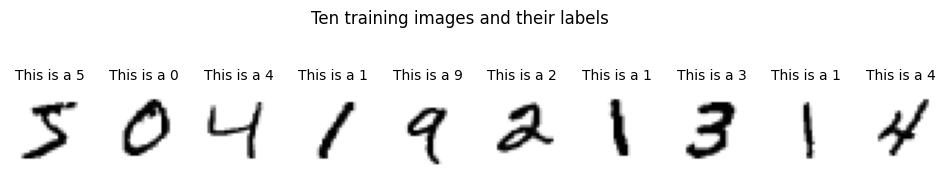

In [ ]:
show_digits(train_images, train_labels, title="Ten training images and their labels")

## Step 2. Normal training: all data collected in one place
First we train the usual way: all 30,000 training images on one computer. This is what federated learning tries to avoid, but it gives us a **target score** to compare against.

It trains 5 times over the data, the same as 5 federated rounds, so the comparison is fair.

In [ ]:
normal_model = Net()
train(normal_model, train_images, train_labels, epochs=5)
baseline = test(normal_model)
print(f"Normal training (all data collected): {baseline:.1%} of the 10,000 test images correct")

Normal training (all data collected): 94.2% of the 10,000 test images correct


**How is it marked?** The model answers each test image, and we compare its answer with the label. Here are its answers for the first ten test images:

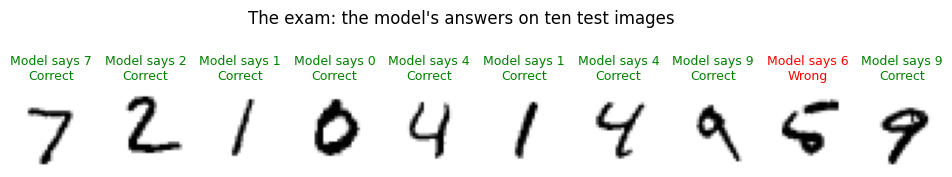

In [ ]:
answers = normal_model(test_images[:10]).argmax(1).tolist()
show_digits(test_images, test_labels, answers, title="The exam: the model's answers on ten test images")

## Step 3. Give each hospital its own data
We split the 30,000 training images into 10 parts, one per hospital (client). From now on, each client can use **only its own part**.

In this first split, every client gets a similar mix of all ten digits (an **even** split).

Hospital 1: 1,500 images
Hospital 2: 1,500 images
Hospital 3: 1,500 images
Hospital 4: 1,500 images
Hospital 5: 1,500 images
Hospital 6: 1,500 images
Hospital 7: 1,500 images
Hospital 8: 1,500 images
Hospital 9: 1,500 images
Hospital 10: 1,500 images
Hospital 11: 1,500 images
Hospital 12: 1,500 images
Hospital 13: 1,500 images
Hospital 14: 1,500 images
Hospital 15: 1,500 images
Hospital 16: 1,500 images
Hospital 17: 1,500 images
Hospital 18: 1,500 images
Hospital 19: 1,500 images
Hospital 20: 1,500 images


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


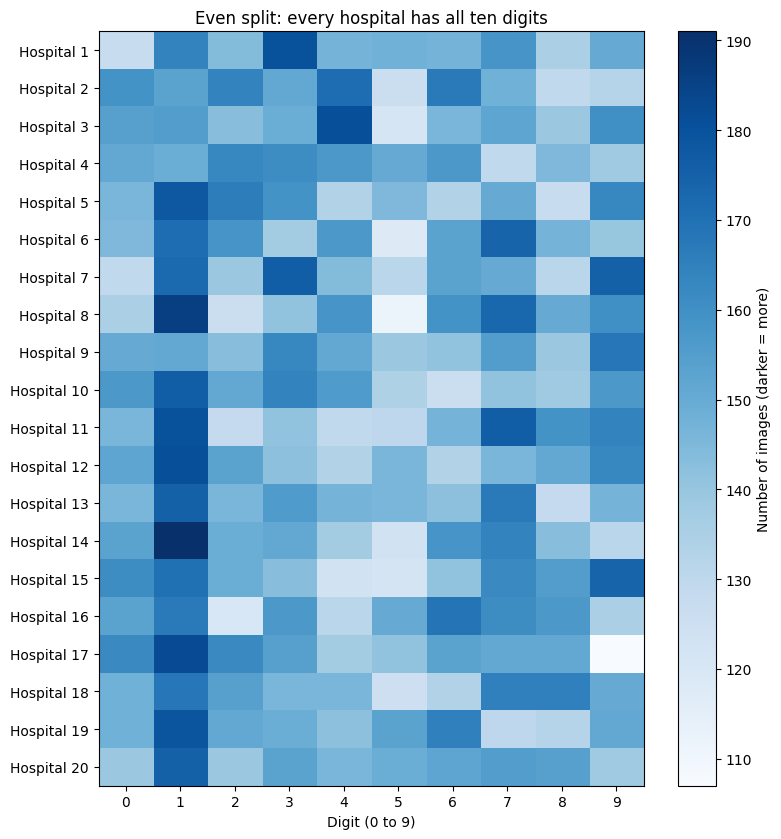

In [ ]:
clients = split_data(num_clients=20, how="even")
for i, c in enumerate(clients):
    print(f"Hospital {i+1}: {len(c):,} images")
show_clients(clients, "Even split: every hospital has all ten digits")

## Step 4. What one client does
This is the most important code in the workshop. It is what each hospital does in every round:
1. **Receive** the current global model from the server.
2. **Train** it on its own images only.
3. **Send back** the updated weights and how many images it used. **No images leave the hospital.**

In [ ]:
def client_training(global_weights, my_images, my_labels):
    """What ONE client (one hospital) does in each round."""
    model = Net()
    model.load_state_dict(global_weights)       # 1. Receive the global model from the server
    train(model, my_images, my_labels)          # 2. Train it on MY OWN images only
    return model.state_dict(), len(my_labels)   # 3. Send back the weights and a count. No images.

print("Client defined.")

Client defined.


**What the server does** each round, inside `run_federated` in the setup cell:

| Step | The server |
|---|---|
| 1. Select | chooses which clients take part this round |
| 2. Send | sends them the current global model |
| 3 and 4 | waits while each client runs `client_training` above |
| 5. Average | combines the returned weights with **FedAvg**, giving more say to clients with more images |
| Check | marks the new global model on the 10,000 test images |

## Step 5. Federated training with the even split
Ten clients, five rounds. Watch the score after each round.

Round 0: before any training ..........................  11.2% correct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Round 1: 20 hospitals trained, server averaged them ...  88.9% correct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Round 2: 20 hospitals trained, server averaged them ...  92.5% correct
Round 3: 20 hospitals trained, server averaged them ...  94.4% correct
Round 4: 20 hospitals trained, server averaged them ...  94.9% correct
Round 5: 20 hospitals trained, server averaged them ...  95.5% correct
Finished in 75 seconds. No hospital shared any image.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


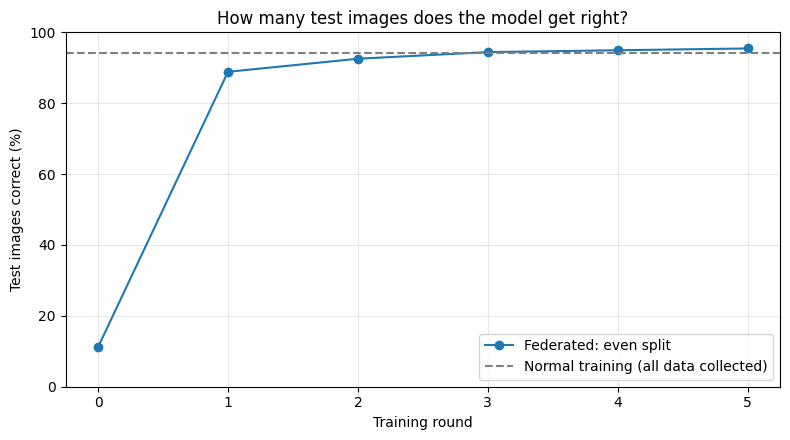

In [ ]:
results = {}
results["Federated: even split"] = run_federated(clients, rounds=5)
plot_results(results, baseline)

**Reading the graph:** the grey dashed line is the target (normal training with all data collected). The blue line is federated learning. If the blue line comes close to the grey line, the hospitals trained a good model without sharing any images.

## Step 6. A harder, more realistic case: uneven data
Real hospitals do not have the same mix of patients. Now each client gets **mostly a few digits** (an **uneven**, or non-IID, split). Look at the picture: each row is dark in only a few columns.

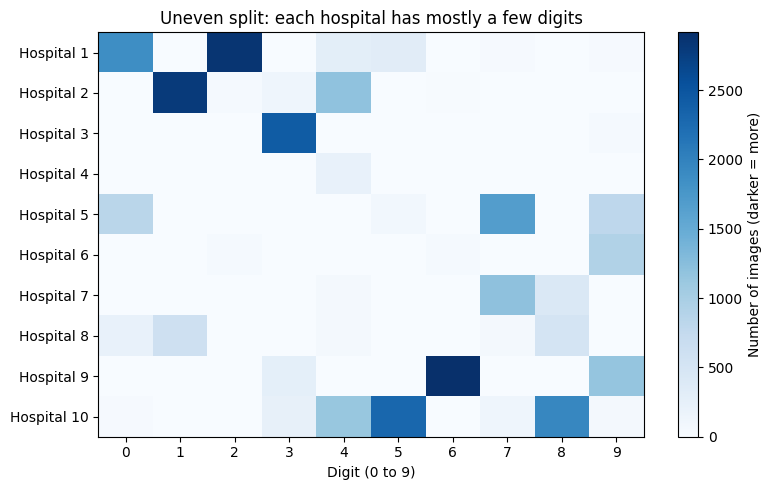

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
uneven_clients = split_data(num_clients=10, how="uneven", alpha=0.1)
show_clients(uneven_clients, "Uneven split: each hospital has mostly a few digits")

Round 0: before any training ..........................   5.4% correct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Round 1: 10 hospitals trained, server averaged them ...  55.8% correct
Round 2: 10 hospitals trained, server averaged them ...  82.7% correct
Round 3: 10 hospitals trained, server averaged them ...  88.7% correct
Round 4: 10 hospitals trained, server averaged them ...  91.4% correct
Round 5: 10 hospitals trained, server averaged them ...  91.2% correct
Finished in 76 seconds. No hospital shared any image.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


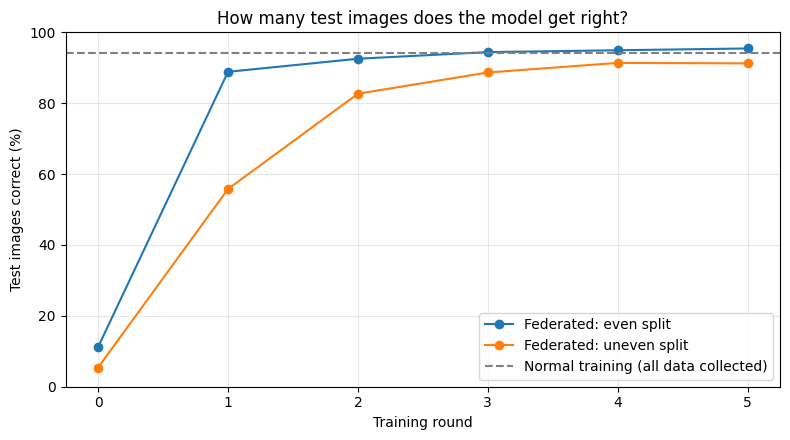

In [ ]:
results["Federated: uneven split"] = run_federated(uneven_clients, rounds=5)
plot_results(results, baseline)

The orange line is lower and less steady. Each client's model becomes good at its own few digits, and averaging models that disagree gives slower progress.

## Step 7. Summary

In [ ]:
print(f"Normal training (all data collected):  {baseline:.1%}")
print(f"Federated, even split:                 {results['Federated: even split'][-1]:.1%}")
print(f"Federated, uneven split:               {results['Federated: uneven split'][-1]:.1%}")

Normal training (all data collected):  94.2%
Federated, even split:                 95.5%
Federated, uneven split:               91.2%


1. Federated learning came close to the target **without moving any image**.
2. Uneven data makes learning slower and less stable. This is a main research problem in federated learning.
3. In Part 4 you will change the number of clients, how uneven the data is, and how many clients train each round.

**Further reading:** McMahan et al. (2017), *Communication-Efficient Learning of Deep Networks from Decentralized Data*, AISTATS. Flower documentation: https://flower.ai/docs